<a href="https://colab.research.google.com/github/laiajufresa-code/TFG/blob/main/TFG_LLIBRETA5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LLIBRETA 5 · Prototip de suport a la decisió: prioritat, explicació i recomanacions

**Objectiu:** convertir el model en una eina útil per a l'equip assistencial. Per a cada pacient, el prototip:

1. **Classifica** el nivell de risc (Low, Moderate, High, Critical).
2. **Prioritza:** calcula una **puntuació de prioritat** = probabilitat que el pacient estigui en risc alt o crític, P(High) + P(Critical). Permet ordenar la llista de pacients de més a menys urgent.
3. **Explica el perquè** amb **SHAP**: quines variables fan pujar el risc d'aquest pacient concret.
4. **Proposa recomanacions** segons el tipus de factor, prioritzant els **hàbits i l'adherència** abans de modificar el tractament (inèrcia terapèutica, Khunti 2018).

**Escenari per defecte: E4 (història clínica + smartwatch)**, que és el telemonitoratge entre visites més habitual i no depèn de cap sensor finançat. Es pot canviar a la Cel·la 2 segons els resultats de la Llibreta 4.

### Decisions metodològiques

1. **Mateixa partició, caixes i graelles que les Llibretes 3 i 4.**
2. **Models candidats: Logistic Regression, Random Forest i XGBoost.** Es tria el millor per l'F1 de la validació creuada. No s'hi inclouen SVM, KNN ni Naive Bayes: per a un prototip interessa un model ràpid, amb probabilitats fiables i fàcil d'explicar (a la Llibreta 3, KNN i RF sobreajustaven i NB era poc precís).
3. **Per què P(High) + P(Critical) i no només la classe predita:** dos pacients classificats com a *High* poden tenir probabilitats molt diferents d'estar en risc crític. La puntuació permet ordenar dins de cada classe. Es comprova que estigui **ben calibrada** (que un 0,7 vulgui dir realment un 70 %).
4. **SHAP aplicat a la puntuació de prioritat:** els valors SHAP són en **punts de probabilitat**. Per exemple, "+0,12" vol dir que aquella variable suma 12 punts percentuals a la probabilitat de risc alt o crític d'aquell pacient. S'usa el mètode de permutació, que funciona igual per a qualsevol model.
5. **Recomanacions i simulació "què passaria si":** són **il·lustratives**. El model aprèn associacions, no causes; la simulació mostra com canviaria la predicció, no l'efecte clínic real d'una intervenció.

### Limitació important
El dataset és **transversal**: cada fila és un pacient diferent en un sol moment. El prototip explica **per què un pacient té risc alt ara**, però no pot explicar **per què ha empitjorat** des de l'última visita, perquè no hi ha mesures repetides del mateix pacient. Amb dades reals de seguiment, la mateixa arquitectura podria comparar visites.

### Estructura

| Bloc | Cel·les |
|---|---|
| 0 · Llibreries, paràmetres, escenaris i dades | 1 – 4 |
| 1 · Model del prototip | 5 |
| 2 · Puntuació de prioritat i triatge | 6 – 8 |
| 3 · Explicabilitat global (SHAP) | 9 |
| 4 · Informe per pacient, recomanacions i prototip | 10 – 12 |

## BLOC 0 · Preparació
### Cel·la 1 · Llibreries i càrrega de les dades
Si la llibreria `shap` no està instal·lada a Colab, s'instal·la automàticament.

In [1]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (f1_score, roc_auc_score, confusion_matrix, precision_recall_fscore_support,
                             brier_score_loss, classification_report)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
import kagglehub

try:
    import shap
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"], check=True)
    import shap

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None); pd.set_option("display.width", 250)

path = kagglehub.dataset_download("colabsss/diabetes-risk-monitoring-dataset")
csv_path = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)[0]
df_raw = pd.read_csv(csv_path)
print("Dades:", df_raw.shape, "· shap", shap.__version__)

Using Colab cache for faster access to the 'diabetes-risk-monitoring-dataset' dataset.
Dades: (15000, 35) · shap 0.54.1


### Cel·la 2 · Paràmetres (es canvien NOMÉS aquí)
- `ESCENARI_PROTOTIP`: escenari de la Llibreta 4 amb què es construeix el prototip.
- `N_SHAP` / `N_FONS`: pacients del test que s'expliquen amb SHAP i pacients de referència (fons). Com més grans, més precís i més lent.
- `LLINDARS_PRIORITAT`: talls de la puntuació per definir 4 nivells de prioritat. **Són il·lustratius**: en un entorn real els hauria de fixar l'equip clínic segons la seva capacitat d'atenció.

In [2]:
# ======================= PARÀMETRES =======================
SEED       = 42
TEST_SIZE  = 0.20
K_FOLDS    = 5
METRICA    = "f1_macro"
N_JOBS     = -1
MODE_RAPID = False

ESCENARI_PROTOTIP = "E4"
MODELS_CANDIDATS  = ["Logistic Regression", "Random Forest", "XGBoost"]
N_SHAP = 300             # pacients del test explicats amb SHAP (gràfics globals)
N_FONS = 100             # pacients del training usats com a referència (fons) per SHAP
LLINDARS_PRIORITAT = [0.20, 0.50, 0.80]
NIVELLS_PRIORITAT  = ["P4 · Seguiment habitual", "P3 · Revisar hàbits a la propera visita",
                      "P2 · Avançar la visita", "P1 · Contactar en 48 h"]
# ==========================================================

TARGET = "diabetes_risk_level"
ORDER  = ["Low_Risk", "Moderate_Risk", "High_Risk", "Critical_Risk"]
ETIQ   = ["Low", "Moderate", "High", "Critical"]
PAL4   = ["#2ca02c", "#f2c94c", "#f2994a", "#d62728"]
ID_COLS = ["patient_id", "monitoring_date"]
CAT_BIN = ["gender", "family_history_diabetes", "medication_change_recent"]
CODI_BIN = {"gender": {"Female": 0, "Male": 1}, "family_history_diabetes": {"No": 0, "Yes": 1},
            "medication_change_recent": {"No": 0, "Yes": 1}}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11, "axes.labelsize": 10})
np.random.seed(SEED)

### Cel·la 3 · Escenaris, noms clínics i recomanacions
- Els **blocs i escenaris** són els mateixos que a la Llibreta 4.
- Cada variable té un **nom clínic** (per als informes) i una **categoria**: hàbits i adherència (modificables), constants, control glucèmic, tractament, pes i perfil (no modificable).
- Cada variable té una **recomanació associada** per quan fa pujar el risc. Són recomanacions orientatives d'un prototip, no protocols clínics validats.

In [3]:
BLOCS = {
    "Història clínica i consulta": ["age", "gender", "bmi", "family_history_diabetes", "diabetes_duration_years",
                                    "systolic_bp_mmhg", "diastolic_bp_mmhg", "insulin_dose_units",
                                    "medication_change_recent", "comorbidity_count", "outpatient_visits_6m"],
    "Analítica de sang":           ["hba1c_percent", "glucose_fasting_mg_dl"],
    "Smartwatch":                  ["heart_rate_bpm", "heart_rate_variability_ms", "spo2_percent", "body_temperature_c",
                                    "physical_activity_min", "step_count", "calories_burned", "sedentary_duration_hr",
                                    "sleep_duration_hr", "sleep_quality_score", "stress_level_score"],
    "CGM (sensor de glucosa)":     ["sensor_glucose_variability", "daily_monitoring_frequency", "abnormal_glucose_events"],
    "Recollida dubtosa":           ["glucose_postprandial_mg_dl", "medication_adherence_pct", "previous_hypoglycemia_events",
                                    "water_intake_l", "carbohydrate_intake_g"],
}
HCE, LAB, WATCH, CGM, DUBT = BLOCS.values()
PREDICTORES = [c for c in df_raw.columns if c not in ID_COLS + [TARGET]]
ordenar = lambda cols: [c for c in PREDICTORES if c in set(cols)]
ESCENARIS = {"E1": ("Només smartwatch", ordenar(WATCH)),
             "E2": ("Consulta sense analítica", ordenar(HCE)),
             "E3": ("Consulta completa", ordenar(HCE + LAB)),
             "E4": ("Història clínica + smartwatch", ordenar(HCE + WATCH)),
             "E5": ("Història clínica + smartwatch + CGM", ordenar(HCE + WATCH + CGM)),
             "E6": ("Tot", list(PREDICTORES))}
NOM_ESC, COLS = ESCENARIS[ESCENARI_PROTOTIP]

NOMS = {"age": "Edat", "gender": "Gènere (home)", "bmi": "IMC", "family_history_diabetes": "Antecedents familiars",
        "diabetes_duration_years": "Anys amb diabetis", "hba1c_percent": "HbA1c", "glucose_fasting_mg_dl": "Glucosa en dejú",
        "glucose_postprandial_mg_dl": "Glucosa postprandial", "heart_rate_bpm": "Freqüència cardíaca",
        "heart_rate_variability_ms": "Variabilitat de la FC (VFC)", "systolic_bp_mmhg": "Tensió sistòlica",
        "diastolic_bp_mmhg": "Tensió diastòlica", "spo2_percent": "Saturació d'O2", "body_temperature_c": "Temperatura",
        "physical_activity_min": "Activitat física (min)", "step_count": "Passos", "calories_burned": "Calories cremades",
        "sedentary_duration_hr": "Hores de sedentarisme", "sleep_duration_hr": "Hores de son",
        "sleep_quality_score": "Qualitat del son", "stress_level_score": "Nivell d'estrès", "water_intake_l": "Aigua (L)",
        "carbohydrate_intake_g": "Hidrats de carboni (g)", "sensor_glucose_variability": "Variabilitat de la glucosa (CGM)",
        "daily_monitoring_frequency": "Autocontrols diaris", "abnormal_glucose_events": "Episodis de glucosa anòmala",
        "medication_adherence_pct": "Adherència a la medicació", "insulin_dose_units": "Dosi d'insulina",
        "medication_change_recent": "Canvi recent de medicació", "previous_hypoglycemia_events": "Hipoglucèmies prèvies",
        "comorbidity_count": "Comorbiditats", "outpatient_visits_6m": "Visites (6 mesos)"}

CATEGORIA = {}
for c in ["physical_activity_min", "step_count", "calories_burned", "sedentary_duration_hr", "sleep_duration_hr",
          "sleep_quality_score", "stress_level_score", "water_intake_l", "carbohydrate_intake_g"]:
    CATEGORIA[c] = "Hàbits (modificable)"
CATEGORIA["medication_adherence_pct"] = "Adherència (modificable)"
for c in ["heart_rate_bpm", "heart_rate_variability_ms", "spo2_percent", "body_temperature_c", "systolic_bp_mmhg", "diastolic_bp_mmhg"]:
    CATEGORIA[c] = "Constants"
for c in ["hba1c_percent", "glucose_fasting_mg_dl", "glucose_postprandial_mg_dl", "sensor_glucose_variability",
          "abnormal_glucose_events", "previous_hypoglycemia_events", "daily_monitoring_frequency"]:
    CATEGORIA[c] = "Control glucèmic"
for c in ["insulin_dose_units", "medication_change_recent"]:
    CATEGORIA[c] = "Tractament"
CATEGORIA["bmi"] = "Pes (modificable a llarg termini)"
for c in ["age", "gender", "family_history_diabetes", "diabetes_duration_years", "comorbidity_count", "outpatient_visits_6m"]:
    CATEGORIA[c] = "Perfil (no modificable)"
MODIFICABLES = [c for c, k in CATEGORIA.items() if k in ("Hàbits (modificable)", "Adherència (modificable)")]

# Sentit clínic esperat: +1 = un valor ALT augmenta el risc · -1 = un valor BAIX augmenta el risc · 0 = sense sentit clar
SENTIT = {c: 0 for c in PREDICTORES}
SENTIT.update({c: +1 for c in ["stress_level_score", "sedentary_duration_hr", "hba1c_percent", "glucose_fasting_mg_dl",
                               "glucose_postprandial_mg_dl", "sensor_glucose_variability", "abnormal_glucose_events",
                               "previous_hypoglycemia_events", "heart_rate_bpm", "body_temperature_c", "systolic_bp_mmhg",
                               "diastolic_bp_mmhg", "bmi", "carbohydrate_intake_g", "age", "diabetes_duration_years",
                               "comorbidity_count"]})
SENTIT.update({c: -1 for c in ["physical_activity_min", "step_count", "calories_burned", "sleep_duration_hr",
                               "sleep_quality_score", "medication_adherence_pct", "heart_rate_variability_ms", "spo2_percent"]})

R_ACT = "Pactar un pla d'activitat física progressiu i adaptat."
R_CONST = "Revisar constants i descartar un procés intercurrent (p. ex., una infecció)."
R_TA = "Controlar la tensió arterial i revisar-ne el tractament."
R_GLU = "Control glucèmic insuficient: valorar ajust terapèutic."
R_CGM = "Revisar les dades del sensor (temps en rang, hipoglucèmies i hiperglucèmies)."
R_TRACT = "Revisar la pauta de tractament, un cop descartats factors d'hàbits i adherència."
R_PERF = "Factor de base no modificable: justifica un seguiment més estret."
RECOMANACIO = {"physical_activity_min": R_ACT, "step_count": R_ACT, "calories_burned": R_ACT,
               "sedentary_duration_hr": "Reduir les hores assegut amb pauses actives durant el dia.",
               "sleep_duration_hr": "Revisar els hàbits de son (horaris, pantalles, cafeïna).",
               "sleep_quality_score": "Explorar la qualitat del son; si persisteix, valorar un trastorn del son.",
               "stress_level_score": "Valorar l'estrès i oferir educació o suport psicològic.",
               "water_intake_l": "Revisar la hidratació.",
               "carbohydrate_intake_g": "Revisar la ingesta d'hidrats amb educació nutricional.",
               "medication_adherence_pct": "Revisar l'adherència: barreres, comprensió de la pauta i dispensació.",
               "heart_rate_bpm": R_CONST, "heart_rate_variability_ms": "VFC alterada: correlacionar amb estrès i son.",
               "spo2_percent": R_CONST, "body_temperature_c": R_CONST, "systolic_bp_mmhg": R_TA, "diastolic_bp_mmhg": R_TA,
               "hba1c_percent": R_GLU, "glucose_fasting_mg_dl": R_GLU, "glucose_postprandial_mg_dl": R_GLU,
               "sensor_glucose_variability": R_CGM, "abnormal_glucose_events": R_CGM,
               "previous_hypoglycemia_events": "Antecedents d'hipoglucèmia: extremar la precaució abans d'augmentar la insulina.",
               "daily_monitoring_frequency": "Revisar la freqüència d'autocontrol.",
               "insulin_dose_units": R_TRACT, "medication_change_recent": R_TRACT,
               "bmi": "Consell nutricional i pla de pes a mitjà termini.",
               "age": R_PERF, "gender": R_PERF, "family_history_diabetes": R_PERF, "diabetes_duration_years": R_PERF,
               "comorbidity_count": R_PERF, "outpatient_visits_6m": R_PERF}
assert set(NOMS) == set(CATEGORIA) == set(RECOMANACIO) == set(PREDICTORES)
print(f"Escenari del prototip: {ESCENARI_PROTOTIP} · {NOM_ESC} · {len(COLS)} variables")
display(pd.DataFrame({"Nom clínic": [NOMS[c] for c in COLS], "Categoria": [CATEGORIA[c] for c in COLS]}, index=COLS))

Escenari del prototip: E4 · Història clínica + smartwatch · 22 variables


,Nom clínic,Categoria
age,Edat,Perfil (no modificable)
gender,Gènere (home),Perfil (no modificable)
bmi,IMC,Pes (modificable a llarg termini)
family_history_diabetes,Antecedents familiars,Perfil (no modificable)
diabetes_duration_years,Anys amb diabetis,Perfil (no modificable)
heart_rate_bpm,Freqüència cardíaca,Constants
systolic_bp_mmhg,Tensió sistòlica,Constants
diastolic_bp_mmhg,Tensió diastòlica,Constants
spo2_percent,Saturació d'O2,Constants
body_temperature_c,Temperatura,Constants


### Cel·la 4 · Dades, partició i caixes (les mateixes de sempre)
Les 3 variables binàries es codifiquen com a 0/1 (home = 1, sí = 1). El model és **idèntic** al de les llibretes anteriors, perquè l'`OneHotEncoder` produeix la mateixa columna. Així, l'explicador SHAP pot treballar amb dades només numèriques.

In [4]:
X = df_raw.drop(columns=ID_COLS + [TARGET]).copy()
for c, mapa in CODI_BIN.items():
    X[c] = X[c].map(mapa).astype(int)
y = pd.Series(pd.Categorical(df_raw[TARGET], categories=ORDER, ordered=True).codes, index=X.index, name="risc")
assert (y >= 0).all() and X.notna().all().all()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
FOLDS = list(StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED).split(X_train, y_train))
Xtr, Xte = X_train[COLS], X_test[COLS]
print(f"Training: {len(Xtr)} · Test: {len(Xte)} · variables: {len(COLS)}")

Training: 12000 · Test: 3000 · variables: 22


## BLOC 1 · Model del prototip
### Cel·la 5 · Selecció del model (Grid Search amb les mateixes caixes)
Es comparen els 3 candidats amb validació creuada i es tria el de més **F1 macro a la CV**. El model final s'entrena amb tot el training i s'avalua una sola vegada al test. Es mostren la sensibilitat de cada classe i la matriu de confusió.

Logistic Regression: F1 CV = 0.6081 ± 0.0092 · 21 s
Random Forest: F1 CV = 0.5862 ± 0.0057 · 716 s
XGBoost: F1 CV = 0.5898 ± 0.0159 · 246 s

MODEL DEL PROTOTIP: Logistic Regression · {'model__C': 10, 'model__class_weight': None}
Test · F1 macro = 0.6177 · AUC = 0.8648


,Precision,Sensibilitat,F1,n
Low,0.775,0.817,0.795,1200
Moderate,0.512,0.536,0.524,900
High,0.520,0.487,0.503,600
Critical,0.742,0.577,0.649,300


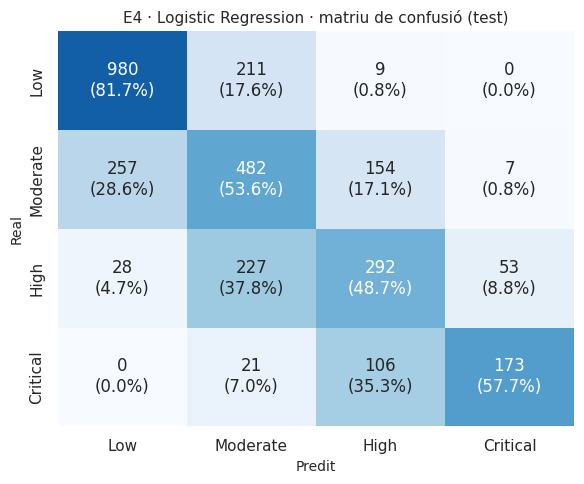

In [5]:
def preprocessador(cols):
    num = [c for c in cols if c not in CAT_BIN]; cat = [c for c in cols if c in CAT_BIN]
    trans = [("num", StandardScaler(), num)]
    if cat:
        trans.append(("cat", OneHotEncoder(drop="if_binary", sparse_output=False, handle_unknown="ignore"), cat))
    return ColumnTransformer(trans, remainder="drop")

CW = [None, "balanced"]
GRAELLES = {
    "Logistic Regression": (LogisticRegression(max_iter=5000, random_state=SEED),
                            {"model__C": [0.01, 0.1, 1, 10, 100], "model__class_weight": CW}),
    "Random Forest": (RandomForestClassifier(random_state=SEED, n_jobs=1),
                      {"model__n_estimators": [200, 400], "model__max_depth": [None, 12],
                       "model__min_samples_leaf": [1, 4], "model__class_weight": CW}),
    "XGBoost": (XGBClassifier(objective="multi:softprob", eval_metric="mlogloss", tree_method="hist", random_state=SEED, n_jobs=1),
                {"model__n_estimators": [200, 400], "model__max_depth": [3, 5],
                 "model__learning_rate": [0.05, 0.1], "model__subsample": [0.8, 1.0]}),
}
if MODE_RAPID:
    GRAELLES = {m: (e, {k: v[:1] for k, v in g.items()}) for m, (e, g) in GRAELLES.items()}

cand = {}
for nom in MODELS_CANDIDATS:
    est, g = GRAELLES[nom]; t0 = time.time()
    gs = GridSearchCV(Pipeline([("prep", preprocessador(COLS)), ("model", clone(est))]), g, scoring=METRICA,
                      cv=FOLDS, n_jobs=N_JOBS, refit=False).fit(Xtr, y_train)
    i = gs.best_index_
    f1s = [gs.cv_results_[f"split{f}_test_score"][i] for f in range(K_FOLDS)]
    cand[nom] = {"params": gs.best_params_, "F1 CV": np.mean(f1s), "SD": np.std(f1s, ddof=1)}
    print(f"{nom}: F1 CV = {np.mean(f1s):.4f} ± {np.std(f1s, ddof=1):.4f} · {time.time() - t0:.0f} s")

MODEL_NOM = max(cand, key=lambda m: cand[m]["F1 CV"])
est, _ = GRAELLES[MODEL_NOM]
MODEL = Pipeline([("prep", preprocessador(COLS)), ("model", clone(est))]).set_params(**cand[MODEL_NOM]["params"]).fit(Xtr, y_train)

PROBA = MODEL.predict_proba(Xte); PRED = PROBA.argmax(axis=1)
p, r, f, n = precision_recall_fscore_support(y_test, PRED, labels=range(4), zero_division=0)
print(f"\nMODEL DEL PROTOTIP: {MODEL_NOM} · {cand[MODEL_NOM]['params']}")
print(f"Test · F1 macro = {f1_score(y_test, PRED, average='macro'):.4f} · AUC = {roc_auc_score(y_test, PROBA, multi_class='ovr'):.4f}")
display(pd.DataFrame({"Precision": p, "Sensibilitat": r, "F1": f, "n": n}, index=ETIQ).round(3))

cm = confusion_matrix(y_test, PRED, labels=range(4)); cmn = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cmn, annot=np.array([[f"{cm[i, j]}\n({cmn[i, j]:.1%})" for j in range(4)] for i in range(4)]), fmt="",
            cmap="Blues", vmin=0, vmax=1, cbar=False, xticklabels=ETIQ, yticklabels=ETIQ, ax=ax)
ax.set(title=f"{ESCENARI_PROTOTIP} · {MODEL_NOM} · matriu de confusió (test)", xlabel="Predit", ylabel="Real")
plt.tight_layout(); plt.show()

## BLOC 2 · Puntuació de prioritat i triatge
### Cel·la 6 · Puntuació de prioritat: P(High) + P(Critical)
La puntuació va de 0 a 1 i és la probabilitat, segons el model, que el pacient estigui en risc alt o crític.

- **Boxplot:** com es distribueix la puntuació segons la classe real. Si és útil, ha de pujar de Low a Critical.
- **Corba de calibratge:** l'eix X és la puntuació predita (agrupada en 10 intervals) i l'eix Y la proporció real de pacients High o Critical en cada interval. Si els punts cauen sobre la diagonal, la puntuació és fiable com a probabilitat. Ho resumeix el **Brier score** (0 = perfecte).
- **Taula de nivells de prioritat:** quants pacients de cada classe real cauen a cada nivell (P1 – P4) amb els llindars de la Cel·la 2.

AUC de la puntuació per detectar pacients reals High o Critical: 0.9193
Brier score: 0.1021


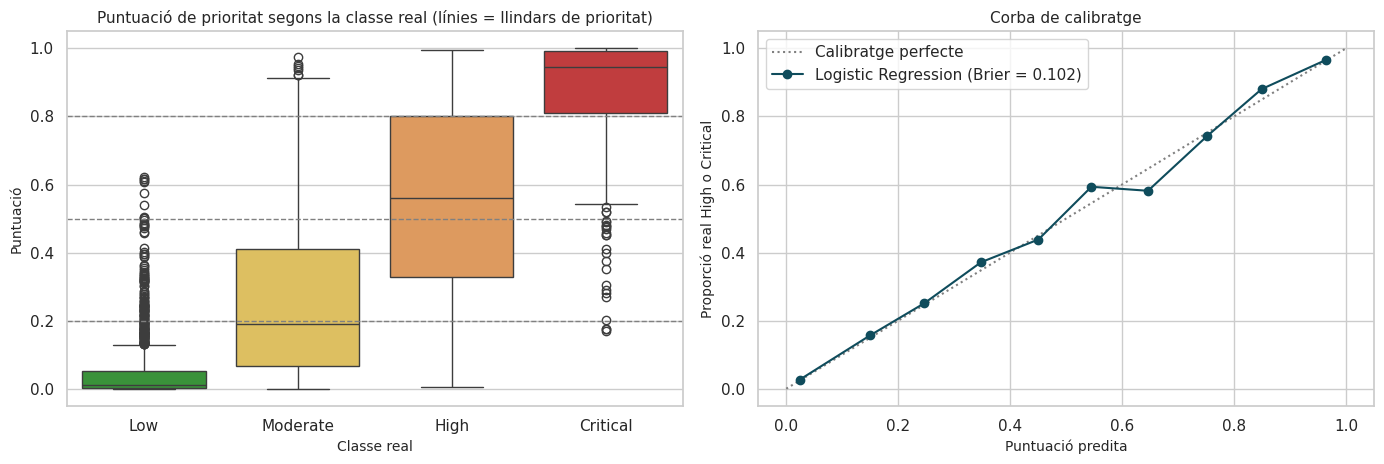

Classe real,Low,Moderate,High,Critical,Total
Nivell de prioritat,,,,,
P1 · Contactar en 48 h,0,26,153,229,408
P2 · Avançar la visita,10,137,199,50,396
P3 · Revisar hàbits a la propera visita,82,273,167,18,540
P4 · Seguiment habitual,1108,464,81,3,1656
Total,1200,900,600,300,3000


In [6]:
def puntuacio(proba):
    return proba[:, 2] + proba[:, 3]

def nivell(score):
    return NIVELLS_PRIORITAT[int(np.digitize(score, LLINDARS_PRIORITAT))]

SCORE = pd.Series(puntuacio(PROBA), index=Xte.index, name="Puntuació")
ALT = (y_test >= 2).astype(int)                 # real High o Critical

print(f"AUC de la puntuació per detectar pacients reals High o Critical: {roc_auc_score(ALT, SCORE):.4f}")
print(f"Brier score: {brier_score_loss(ALT, SCORE):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
d = pd.DataFrame({"Puntuació": SCORE, "Classe real": pd.Categorical([ETIQ[k] for k in y_test], ETIQ, ordered=True)})
sns.boxplot(data=d, x="Classe real", y="Puntuació", hue="Classe real", palette=PAL4, legend=False, ax=axes[0])
for t in LLINDARS_PRIORITAT:
    axes[0].axhline(t, ls="--", color="grey", lw=1)
axes[0].set_title("Puntuació de prioritat segons la classe real (línies = llindars de prioritat)")
fr, mp = calibration_curve(ALT, SCORE, n_bins=10, strategy="uniform")
axes[1].plot([0, 1], [0, 1], ":", color="grey", label="Calibratge perfecte")
axes[1].plot(mp, fr, "-o", color="#0F4C5C", label=f"{MODEL_NOM} (Brier = {brier_score_loss(ALT, SCORE):.3f})")
axes[1].set(xlabel="Puntuació predita", ylabel="Proporció real High o Critical", title="Corba de calibratge"); axes[1].legend()
plt.tight_layout(); plt.show()

NIVELL = SCORE.apply(nivell)
tab = pd.crosstab(pd.Categorical(NIVELL, NIVELLS_PRIORITAT[::-1], ordered=True),
                  pd.Categorical([ETIQ[k] for k in y_test], ETIQ, ordered=True), margins=True, margins_name="Total")
tab.index.name, tab.columns.name = "Nivell de prioritat", "Classe real"
display(tab)

### Cel·la 7 · Corba de captura: si visitem primer els pacients amb més puntuació, quants greus trobem?
S'ordenen els 3.000 pacients del test de més a menys puntuació. L'eix X és el **percentatge de pacients revisats** (començant pels de més puntuació) i l'eix Y el **percentatge de pacients greus que ja s'han trobat**.

- **Línia vermella:** pacients reals Critical. **Línia taronja:** reals High o Critical.
- **Línia grisa:** revisar els pacients a l'atzar (sense prioritzar).

**Com es llegeix:** si revisant el 20 % de pacients es troba el 90 % dels crítics, la prioritat permet concentrar l'esforç de l'equip on cal. És l'argument principal del triatge.

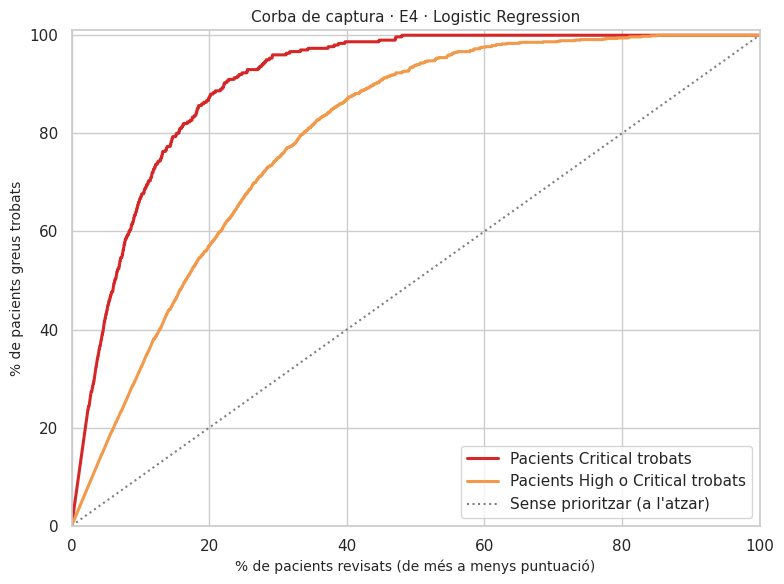

,Revisant el 10 %,Revisant el 20 %,Revisant el 30 %,Revisant el 40 %,Revisant el 50 %
% Critical trobats,66.7,87.3,96.0,98.7,100.0
% High o Critical trobats,32.0,57.1,75.0,87.0,93.9
Sense prioritzar,10.0,20.0,30.0,40.0,50.0


In [7]:
ordre = SCORE.sort_values(ascending=False).index
yy = y_test.loc[ordre].values
frac = np.arange(1, len(yy) + 1) / len(yy)
cap_crit = np.cumsum(yy == 3) / (yy == 3).sum()
cap_alt  = np.cumsum(yy >= 2) / (yy >= 2).sum()

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(frac * 100, cap_crit * 100, color="#d62728", lw=2.2, label="Pacients Critical trobats")
ax.plot(frac * 100, cap_alt * 100, color="#f2994a", lw=2.2, label="Pacients High o Critical trobats")
ax.plot([0, 100], [0, 100], ":", color="grey", label="Sense prioritzar (a l'atzar)")
ax.set(xlabel="% de pacients revisats (de més a menys puntuació)", ylabel="% de pacients greus trobats",
       title=f"Corba de captura · {ESCENARI_PROTOTIP} · {MODEL_NOM}", xlim=(0, 100), ylim=(0, 101))
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

punts = [10, 20, 30, 40, 50]
display(pd.DataFrame({f"Revisant el {q} %": {"% Critical trobats": round(cap_crit[int(len(yy) * q / 100) - 1] * 100, 1),
                                                "% High o Critical trobats": round(cap_alt[int(len(yy) * q / 100) - 1] * 100, 1),
                                                "Sense prioritzar": q} for q in punts}))

### Cel·la 8 · Llista de prioritat (vista de l'equip d'infermeria)
Així es veuria la llista diària del prototip: els 15 pacients del test amb més puntuació, amb el nivell de prioritat, la classe predita i (només per avaluar) la classe real.

In [8]:
llista = pd.DataFrame({"Pacient": df_raw.loc[ordre[:15], "patient_id"].values,
                       "Puntuació": SCORE.loc[ordre[:15]].round(3).values,
                       "Nivell de prioritat": NIVELL.loc[ordre[:15]].values,
                       "Classe predita": [ETIQ[k] for k in MODEL.predict(Xte.loc[ordre[:15]])],
                       "Classe real (avaluació)": [ETIQ[k] for k in y_test.loc[ordre[:15]]]}, index=range(1, 16))
display(llista)

,Pacient,Puntuació,Nivell de prioritat,Classe predita,Classe real (avaluació)
1,P10356,1.0,P1 · Contactar en 48 h,Critical,Critical
2,P05321,1.0,P1 · Contactar en 48 h,Critical,Critical
3,P03388,1.0,P1 · Contactar en 48 h,Critical,Critical
4,P09370,1.0,P1 · Contactar en 48 h,Critical,Critical
5,P00114,1.0,P1 · Contactar en 48 h,Critical,Critical
6,P02609,1.0,P1 · Contactar en 48 h,Critical,Critical
7,P06388,1.0,P1 · Contactar en 48 h,Critical,Critical
8,P00779,1.0,P1 · Contactar en 48 h,Critical,Critical
9,P04927,1.0,P1 · Contactar en 48 h,Critical,Critical
10,P01739,1.0,P1 · Contactar en 48 h,Critical,Critical


## BLOC 3 · Explicabilitat global
### Cel·la 9 · SHAP global: quines variables pesen més en la puntuació de prioritat
Per a cada pacient, SHAP reparteix la diferència entre la seva puntuació i la puntuació mitjana entre totes les variables. Cada valor SHAP és en **punts de probabilitat**.

- **Gràfic de barres:** importància mitjana (mitjana del valor absolut de SHAP) de cada variable.
- **Gràfic d'eixam (beeswarm):** cada punt és un pacient. La posició horitzontal indica si la variable li **puja** (dreta) o **baixa** (esquerra) la puntuació, i el color indica si el valor de la variable és **alt** (vermell) o **baix** (blau). Per exemple, si a "Qualitat del son" els punts blaus són a la dreta, una qualitat del son baixa fa pujar el risc.
- **Taula de variables:** importància, sentit de l'efecte al model (si són els valors alts o els baixos els que pugen el risc) i si aquest sentit és **coherent amb la clínica** (per exemple, que un estrès alt o una qualitat del son baixa pugin el risc). Un "✘ revisar" indica una associació que el model ha après però que no té sentit clínic: possible artefacte del dataset.
- **Taula per categoria:** quina part de la importància total ve de factors modificables (hàbits i adherència) i quina de factors no modificables.

**Precaució:** SHAP explica **el model**, no la fisiologia. Si el dataset és sintètic, l'explicació reflecteix com s'han generat les dades. Serveix per comprovar si el model fa servir factors clínicament coherents.

SHAP calculat per a 300 pacients en 11 s · puntuació mitjana de referència = 0.361


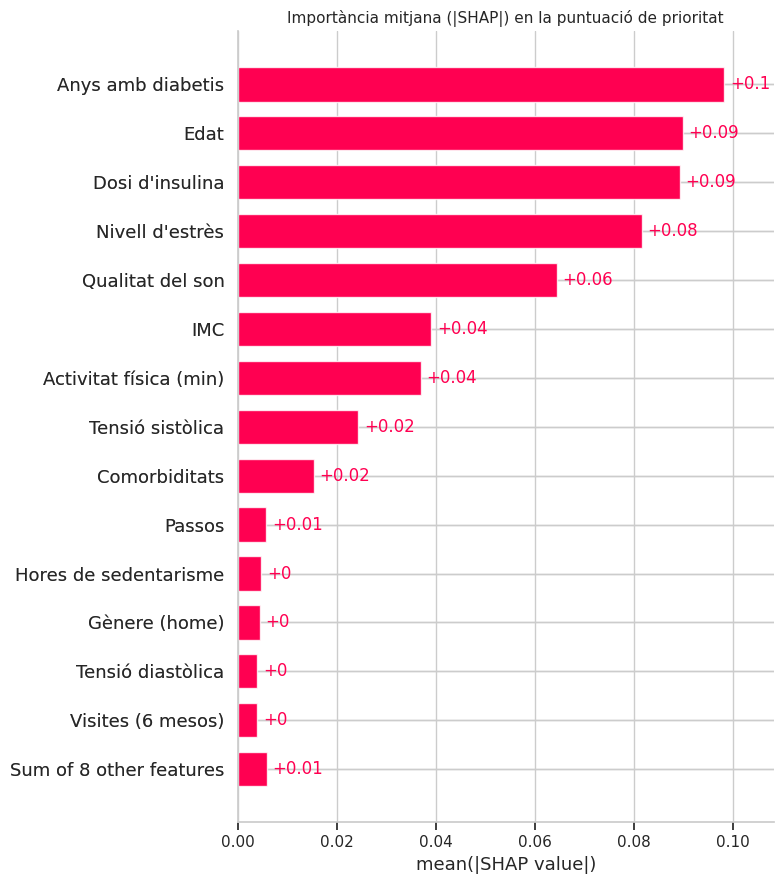

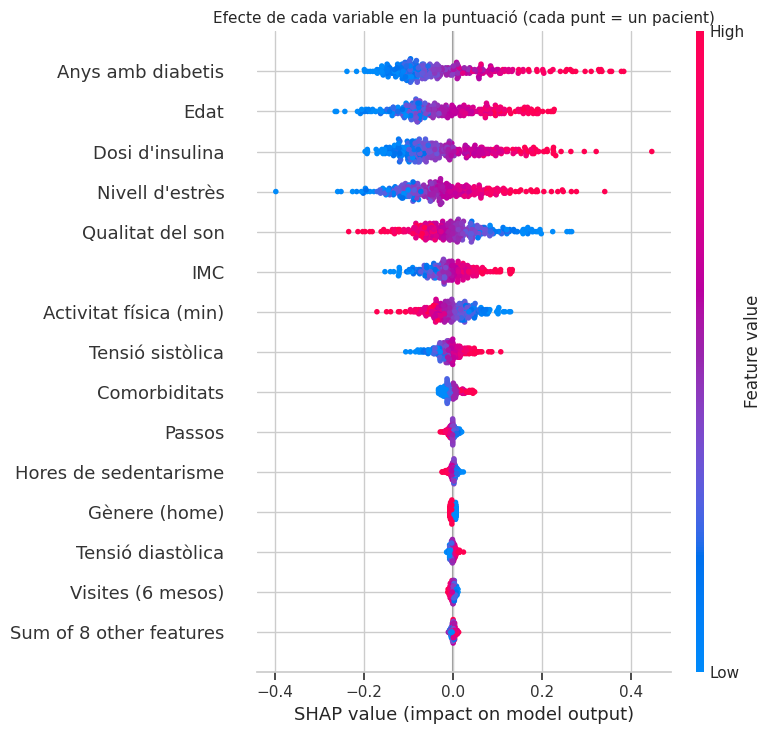

,Categoria,Importància mitjana |SHAP|,% del total,Efecte al model,Coherent amb la clínica?
Variable,,,,,
Anys amb diabetis,Perfil (no modificable),0.0982,17.3,valors alts pugen el risc,✔
Edat,Perfil (no modificable),0.0898,15.8,valors alts pugen el risc,✔
Dosi d'insulina,Tractament,0.0892,15.7,valors alts pugen el risc,—
Nivell d'estrès,Hàbits (modificable),0.0815,14.4,valors alts pugen el risc,✔
Qualitat del son,Hàbits (modificable),0.0644,11.3,valors baixos pugen el risc,✔
IMC,Pes (modificable a llarg termini),0.0391,6.9,valors alts pugen el risc,✔
Activitat física (min),Hàbits (modificable),0.0370,6.5,valors baixos pugen el risc,✔
Tensió sistòlica,Constants,0.0243,4.3,valors alts pugen el risc,✔
Comorbiditats,Perfil (no modificable),0.0154,2.7,valors alts pugen el risc,✔



Importància per categoria (% del total):


,% del total
Categoria,
Perfil (no modificable),37.3
Hàbits (modificable),34.1
Tractament,16.0
Pes (modificable a llarg termini),6.9
Constants,5.7


In [9]:
def f_puntuacio(A):
    D = pd.DataFrame(np.asarray(A, dtype=float), columns=COLS)
    for c in CAT_BIN:
        if c in D:
            D[c] = D[c].round().astype(int)
    return puntuacio(MODEL.predict_proba(D))

FONS = Xtr.sample(N_FONS, random_state=SEED).values.astype(float)
EXPLICADOR = shap.explainers.Permutation(f_puntuacio, shap.maskers.Independent(FONS, max_samples=N_FONS))
MAX_EVALS = 2 * (2 * len(COLS) + 1)
NOMS_COLS = [NOMS[c] for c in COLS]

def explicar(Xs, max_evals=MAX_EVALS):
    e = EXPLICADOR(np.asarray(Xs, dtype=float), max_evals=max_evals, silent=True)
    return shap.Explanation(values=np.asarray(e.values), base_values=np.asarray(e.base_values),
                            data=np.asarray(Xs, dtype=float), feature_names=NOMS_COLS)

t0 = time.time()
XS = Xte.sample(min(N_SHAP, len(Xte)), random_state=SEED)
SV = explicar(XS.values)
print(f"SHAP calculat per a {len(XS)} pacients en {time.time() - t0:.0f} s · puntuació mitjana de referència = {np.mean(SV.base_values):.3f}")

shap.plots.bar(SV, max_display=15, show=False); plt.title("Importància mitjana (|SHAP|) en la puntuació de prioritat"); plt.tight_layout(); plt.show()
shap.plots.beeswarm(SV, max_display=15, show=False); plt.title("Efecte de cada variable en la puntuació (cada punt = un pacient)"); plt.tight_layout(); plt.show()

imp = pd.DataFrame({"Variable": NOMS_COLS, "Categoria": [CATEGORIA[c] for c in COLS],
                    "Importància mitjana |SHAP|": np.abs(SV.values).mean(axis=0)}).sort_values("Importància mitjana |SHAP|", ascending=False)
imp["% del total"] = (imp["Importància mitjana |SHAP|"] / imp["Importància mitjana |SHAP|"].sum() * 100).round(1)
def sentit_model(j):                      # signe de la relació entre el valor de la variable i el seu SHAP
    v, d = SV.values[:, j], XS.values[:, j]
    if np.std(d) == 0 or np.std(v) == 0:
        return 0
    return int(np.sign(pd.Series(d).corr(pd.Series(v), method="spearman")))
txt = {1: "valors alts pugen el risc", -1: "valors baixos pugen el risc", 0: "—"}
sm = {NOMS[c]: sentit_model(j) for j, c in enumerate(COLS)}
imp["Efecte al model"] = imp["Variable"].map(lambda n: txt[sm[n]])
imp["Coherent amb la clínica?"] = [("✔" if sm[NOMS[c]] == SENTIT[c] else "✘ revisar") if SENTIT[c] != 0 else "—"
                                   for c in [k for n in imp["Variable"] for k in COLS if NOMS[k] == n]]
display(imp.round(4).set_index("Variable"))
print("\nImportància per categoria (% del total):")
display(imp.groupby("Categoria")["% del total"].sum().sort_values(ascending=False).to_frame())

## BLOC 4 · Informe per pacient
### Cel·la 10 · Funció `informe_pacient`: el nucli del prototip
Per a un pacient, la funció:
1. Calcula les **probabilitats** de cada classe, la **classe predita**, la **puntuació** i el **nivell de prioritat**.
2. Calcula els **valors SHAP d'aquest pacient** i en treu els **3 factors que més li pugen el risc**. Per a cada factor mostra el valor del pacient, la mediana dels pacients Low del training (com a referència) i la recomanació associada. **Control de coherència:** si el factor puja el risc en una direcció que no té sentit clínic (per exemple, més passos que la referència), s'avisa i no es fa cap recomanació.
3. Aplica la regla clínica de la proposta: si entre els factors hi ha hàbits o adherència **i també** tractament, recomana **abordar primer hàbits i adherència** abans de modificar la pauta d'insulina.
4. **Simulació "què passaria si":** posa els factors modificables al valor típic dels pacients Low i recalcula la puntuació. És una simulació del model, no un efecte clínic demostrat.
5. Dibuixa el **gràfic de cascada (waterfall)**: parteix de la puntuació mitjana i mostra com cada variable la puja (vermell) o la baixa (blau) fins a la puntuació del pacient.

In [10]:
REF_LOW = X_train.loc[y_train == 0, COLS].median()

def informe_pacient(x, titol="Pacient", n_factors=3, grafic=True):
    x = pd.Series(x, dtype=float).reindex(COLS)
    assert x.notna().all(), f"Falten variables: {list(x.index[x.isna()])}"
    proba = MODEL.predict_proba(pd.DataFrame([x.values], columns=COLS).astype({c: int for c in CAT_BIN if c in COLS}))[0]
    sc = proba[2] + proba[3]
    sv = explicar(x.values[None, :], max_evals=10 * (2 * len(COLS) + 1))
    contrib = pd.Series(sv.values[0], index=COLS)

    print("=" * 100)
    print(f"{titol} · escenari {ESCENARI_PROTOTIP} ({NOM_ESC}) · model {MODEL_NOM}")
    print("=" * 100)
    print("Probabilitats: " + " · ".join(f"{e} {p:.1%}" for e, p in zip(ETIQ, proba)))
    print(f"Classe predita: {ETIQ[int(np.argmax(proba))]} · Puntuació de prioritat P(High)+P(Critical) = {sc:.3f} · {nivell(sc)}")

    pugen = contrib[contrib > 0].sort_values(ascending=False).head(n_factors)
    print(f"\nFACTORS QUE MÉS PUGEN EL RISC (punts de probabilitat; referència = mediana dels pacients Low):")
    coherents = []
    for i, (c, v) in enumerate(pugen.items(), 1):
        print(f"  {i}. {NOMS[c]}: {x[c]:.1f} (Low: {REF_LOW[c]:.1f}) · +{v:.3f} · [{CATEGORIA[c]}]")
        dif = np.sign(x[c] - REF_LOW[c])
        if SENTIT[c] != 0 and dif != 0 and dif != SENTIT[c]:
            print("     ⚠ Direcció no esperada clínicament (el valor és millor que el de referència): possible artefacte"
                  " del model o del dataset. No es fa recomanació.")
        else:
            print(f"     → {RECOMANACIO[c]}"); coherents.append(c)
    cats = {CATEGORIA[c] for c in coherents}
    if cats & {"Hàbits (modificable)", "Adherència (modificable)"} and "Tractament" in cats:
        print("\n  ⚠ Hi ha factors d'hàbits o d'adherència i també de tractament: abordar primer hàbits i adherència"
              " abans de modificar la pauta d'insulina (evitar la inèrcia terapèutica i el risc d'hipoglucèmia).")

    modif = [c for c in coherents if c in MODIFICABLES]
    if modif:
        print("\nSIMULACIÓ 'QUÈ PASSARIA SI' (predicció del model, no efecte causal):")
        for c in modif:
            x2 = x.copy(); x2[c] = REF_LOW[c]
            print(f"  · Si {NOMS[c].lower()} fos {REF_LOW[c]:.1f}, la puntuació passaria de {sc:.3f} a {f_puntuacio(x2.values[None, :])[0]:.3f}")
        if len(modif) > 1:
            x2 = x.copy(); x2[modif] = REF_LOW[modif]
            print(f"  · Tots alhora: de {sc:.3f} a {f_puntuacio(x2.values[None, :])[0]:.3f}")
    if grafic:
        shap.plots.waterfall(sv[0], max_display=10, show=False)
        plt.title(f"{titol} · per què té aquesta puntuació"); plt.tight_layout(); plt.show()
    return {"probabilitats": dict(zip(ETIQ, proba.round(4))), "puntuacio": sc, "nivell": nivell(sc),
            "factors": [(NOMS[c], round(v, 4)) for c, v in pugen.items()]}

### Cel·la 11 · Exemples amb pacients del test
Tres casos reals del test per veure com funciona l'informe:
1. El pacient amb **més puntuació** (el primer de la llista de prioritat).
2. Un pacient **predit com a High** amb una puntuació intermèdia.
3. Un pacient **predit com a Moderate** amb la puntuació més alta dins la seva classe (el que està més a prop de pujar de nivell).

Cas 1 · màxima prioritat (P10356, classe real: Critical) · escenari E4 (Història clínica + smartwatch) · model Logistic Regression
Probabilitats: Low 0.0% · Moderate 0.0% · High 0.0% · Critical 100.0%
Classe predita: Critical · Puntuació de prioritat P(High)+P(Critical) = 1.000 · P1 · Contactar en 48 h

FACTORS QUE MÉS PUGEN EL RISC (punts de probabilitat; referència = mediana dels pacients Low):
  1. Anys amb diabetis: 25.0 (Low: 3.4) · +0.272 · [Perfil (no modificable)]
     → Factor de base no modificable: justifica un seguiment més estret.
  2. Dosi d'insulina: 50.9 (Low: 7.0) · +0.236 · [Tractament]
     → Revisar la pauta de tractament, un cop descartats factors d'hàbits i adherència.
  3. Nivell d'estrès: 71.4 (Low: 49.1) · +0.062 · [Hàbits (modificable)]
     → Valorar l'estrès i oferir educació o suport psicològic.

  ⚠ Hi ha factors d'hàbits o d'adherència i també de tractament: abordar primer hàbits i adherència abans de modificar la pauta d'insulina (evitar la inèrcia terap

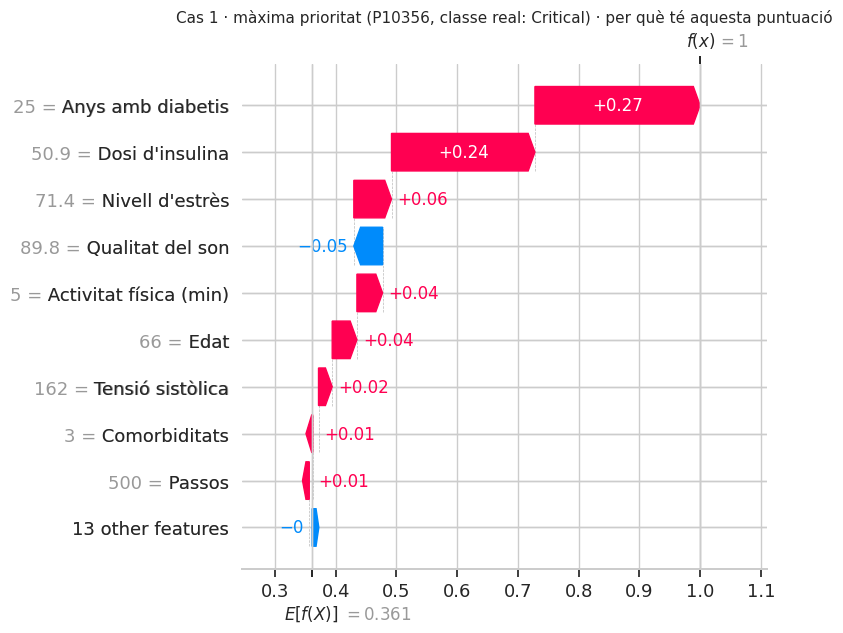

Cas 2 · predit High (P05919, classe real: High) · escenari E4 (Història clínica + smartwatch) · model Logistic Regression
Probabilitats: Low 2.1% · Moderate 28.0% · High 57.0% · Critical 12.9%
Classe predita: High · Puntuació de prioritat P(High)+P(Critical) = 0.699 · P2 · Avançar la visita

FACTORS QUE MÉS PUGEN EL RISC (punts de probabilitat; referència = mediana dels pacients Low):
  1. Qualitat del son: 53.9 (Low: 79.8) · +0.269 · [Hàbits (modificable)]
     → Explorar la qualitat del son; si persisteix, valorar un trastorn del son.
  2. Edat: 72.0 (Low: 37.0) · +0.154 · [Perfil (no modificable)]
     → Factor de base no modificable: justifica un seguiment més estret.
  3. IMC: 35.1 (Low: 26.3) · +0.095 · [Pes (modificable a llarg termini)]
     → Consell nutricional i pla de pes a mitjà termini.

SIMULACIÓ 'QUÈ PASSARIA SI' (predicció del model, no efecte causal):
  · Si qualitat del son fos 79.8, la puntuació passaria de 0.699 a 0.267


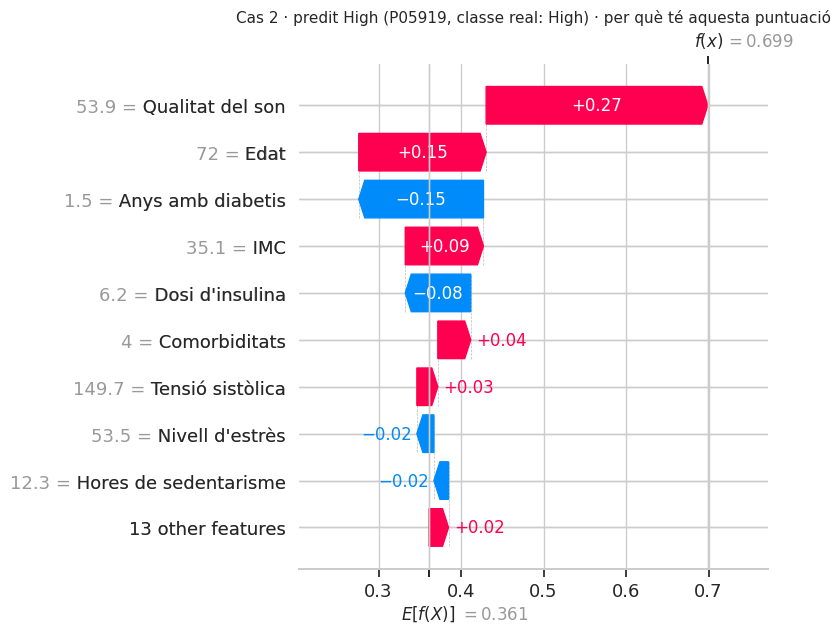

Cas 3 · Moderate a prop de pujar (P09415, classe real: High) · escenari E4 (Història clínica + smartwatch) · model Logistic Regression
Probabilitats: Low 3.9% · Moderate 43.4% · High 42.9% · Critical 9.8%
Classe predita: Moderate · Puntuació de prioritat P(High)+P(Critical) = 0.527 · P2 · Avançar la visita

FACTORS QUE MÉS PUGEN EL RISC (punts de probabilitat; referència = mediana dels pacients Low):
  1. Qualitat del son: 62.8 (Low: 79.8) · +0.169 · [Hàbits (modificable)]
     → Explorar la qualitat del son; si persisteix, valorar un trastorn del son.
  2. Dosi d'insulina: 20.3 (Low: 7.0) · +0.150 · [Tractament]
     → Revisar la pauta de tractament, un cop descartats factors d'hàbits i adherència.
  3. Anys amb diabetis: 7.1 (Low: 3.4) · +0.078 · [Perfil (no modificable)]
     → Factor de base no modificable: justifica un seguiment més estret.

  ⚠ Hi ha factors d'hàbits o d'adherència i també de tractament: abordar primer hàbits i adherència abans de modificar la pauta d'insulina (e

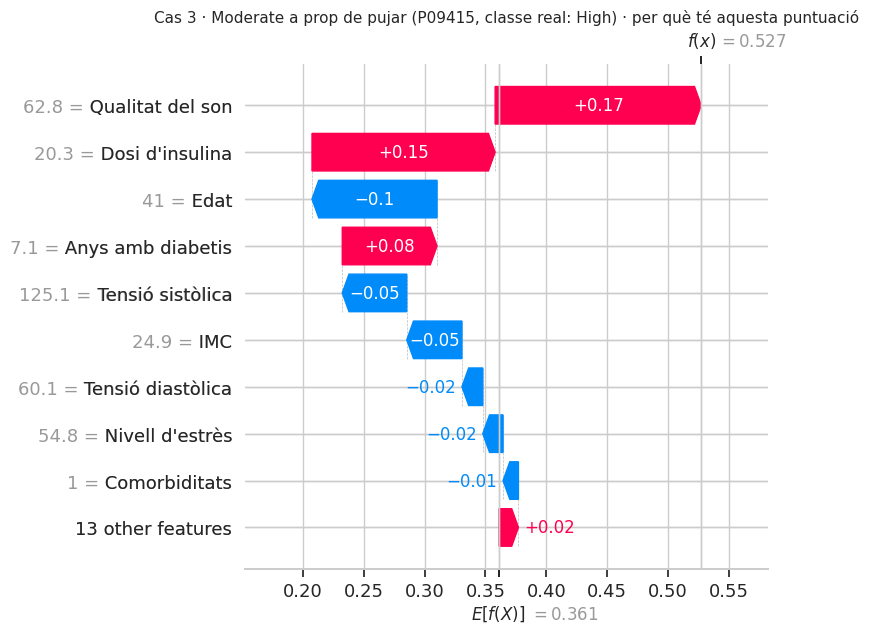

In [11]:
pred_s = pd.Series(PRED, index=Xte.index)
casos = {"Cas 1 · màxima prioritat": SCORE.idxmax()}
alts = SCORE[pred_s == 2]
if len(alts):
    casos["Cas 2 · predit High"] = (alts - alts.median()).abs().idxmin()
mods = SCORE[pred_s == 1]
if len(mods):
    casos["Cas 3 · Moderate a prop de pujar"] = mods.idxmax()
for titol, idx in casos.items():
    informe_pacient(Xte.loc[idx], titol=f"{titol} ({df_raw.loc[idx, 'patient_id']}, classe real: {ETIQ[y_test.loc[idx]]})")

### Cel·la 12 · Prototip amb un pacient nou
Així es faria servir l'eina amb les dades d'un pacient nou. L'exemple parteix dels valors típics (mediana) dels pacients High del training i hi empitjora el son i l'estrès. Per provar-ho amb un altre pacient, n'hi ha prou de canviar els valors del diccionari (les binàries es poden escriure com a text: "Male"/"Female", "Yes"/"No").

Dades del pacient nou (es poden editar):
{'age': 62.0, 'gender': 'Male', 'bmi': 28.2, 'family_history_diabetes': 'No', 'diabetes_duration_years': 6.0, 'heart_rate_bpm': 76.2, 'systolic_bp_mmhg': 144.0, 'diastolic_bp_mmhg': 77.5, 'spo2_percent': 97.5, 'body_temperature_c': 36.7, 'physical_activity_min': 44.9, 'step_count': 3781.5, 'calories_burned': 1680.3, 'sleep_duration_hr': 5.8, 'sleep_quality_score': 63.8, 'sedentary_duration_hr': 9.2, 'insulin_dose_units': 14.2, 'stress_level_score': 69.8, 'heart_rate_variability_ms': 47.1, 'outpatient_visits_6m': 6.0, 'medication_change_recent': 'No', 'comorbidity_count': 2.0}
Pacient nou · escenari E4 (Història clínica + smartwatch) · model Logistic Regression
Probabilitats: Low 0.2% · Moderate 11.2% · High 50.5% · Critical 38.2%
Classe predita: High · Puntuació de prioritat P(High)+P(Critical) = 0.886 · P1 · Contactar en 48 h

FACTORS QUE MÉS PUGEN EL RISC (punts de probabilitat; referència = mediana dels pacients Low):
  1. Nivell d'estrès: 69

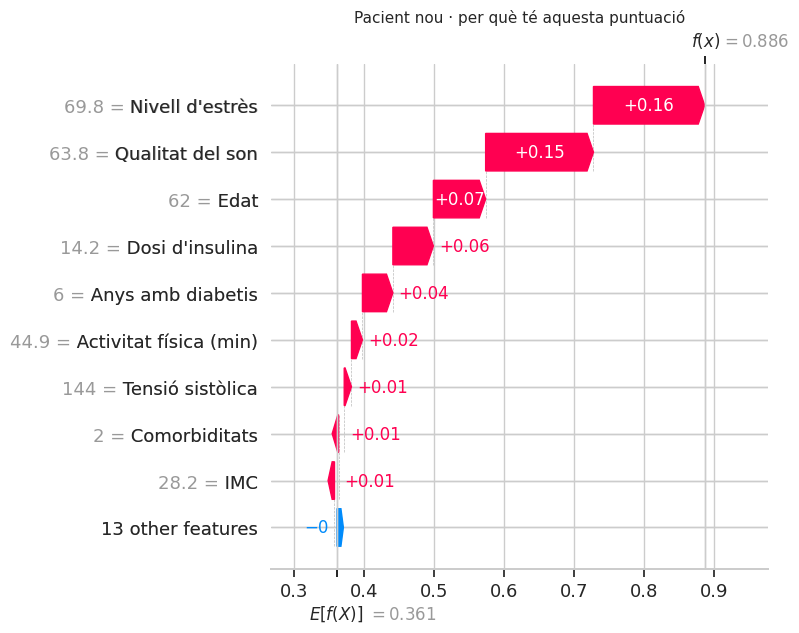

In [12]:
base = X_train.loc[y_train == 2, COLS].median()
pacient_nou = {c: (round(float(v), 1) if c not in CAT_BIN else int(round(v))) for c, v in base.items()}
for c, q in (("sleep_quality_score", 0.10), ("stress_level_score", 0.90), ("sleep_duration_hr", 0.10)):
    if c in pacient_nou:
        pacient_nou[c] = round(float(X_train[c].quantile(q)), 1)
inv = {c: {v: k for k, v in m.items()} for c, m in CODI_BIN.items()}
pacient_nou = {c: (inv[c][v] if c in CAT_BIN else v) for c, v in pacient_nou.items()}
print("Dades del pacient nou (es poden editar):"); print(pacient_nou)

def codificar(d):
    return {c: (CODI_BIN[c][v] if c in CODI_BIN and isinstance(v, str) else v) for c, v in d.items()}

resultat = informe_pacient(codificar(pacient_nou), titol="Pacient nou")

### Conclusions i limitacions (per omplir després d'executar)
**Preguntes guia:**
1. Amb l'escenari triat, quin model guanya i quina sensibilitat té per a Critical i High?
2. La puntuació està ben calibrada? (Corba de calibratge i Brier score.)
3. Revisant el 20 % de pacients amb més puntuació, quin percentatge de crítics es troba? (Corba de captura.)
4. Quines variables pesen més en la puntuació? Quina part de la importància ve de factors modificables (hàbits i adherència)? És clínicament coherent (per exemple, que un son pitjor o un estrès més alt pugin el risc)?
5. Els informes individuals donen recomanacions raonables?

**Limitacions a declarar:**
- **Dades transversals:** el prototip explica el risc actual, però no l'evolució del pacient. Amb dades longitudinals es podria comparar cada visita amb l'anterior.
- **Dataset sintètic:** les explicacions SHAP reflecteixen com s'han generat les dades, no necessàriament la fisiologia.
- **Associació, no causalitat:** la simulació "què passaria si" és una predicció del model, no l'efecte demostrat d'una intervenció.
- **Llindars i recomanacions il·lustratius:** en un entorn real els haurien de definir i validar els professionals, i el producte requeriria certificació (Reglament Europeu de Productes Sanitaris i Llei d'IA europea).
- **Sense etiqueta de tipus de diabetis:** en dades reals caldria valorar models separats per a tipus 1 i tipus 2.